# β-VAE sobre Fashion-MNIST: efecto de β en la calidad de reconstrucción

**INTRODUCCIÓN**

Un Autoencoder es una red neuronal cuyo objetivo consiste en aprender a reconstruir los datos de entrada a partir de una representación comprimida de estos. Para ello, cuenta con un encoder y un decoder, de tal forma que el proceso sería el siguiente:

${x}$ → Encoder → ${z}$ → Decoder → $\hat{x}$  

Donde:  
${x}$: dato original  
${z}$: vector que contiene una representación comprimida de ${x}$  
$\hat{x}$: reconstrucción del dato original

En un Variational Autoencoder (VAE), el encoder no transforma los datos de entrada en un vector fijo, sino que los representa a través de una distribución normal con media $\mu$ y varianza $\sigma^2$. A partir de esta distribución se obtiene el vector ${z}$ mediante la técnica de reparametrización, que permite aplicar retropropagación (ajuste de los pesos de la red) en el entrenamiento.

La función de pérdida de un VAE, además del error de reconstrucción, tiene en cuenta la divergencia de Kullback-Leibler (KL), que fuerza a que la distribución se aproxime a una distribución $\mathcal{N}(0,1)$.

Por otro lado, el Beta-Variational Autoencoder (β-VAE) añade un parámetro β a la función de pérdida que controla el peso que se le da a la divergencia KL, con la finalidad de equilibrar la fidelidad de las reconstrucciones con la estructura del espacio latente.

**OBJETIVO**

El objetivo es entrenar un β-VAE utilizando el conjunto de datos Fashion MNIST, que contiene imágenes de ropa en escala de grises.

Se entrenará la red con distintos valores de β para ver cómo afecta este parámetro a los resultados y la calidad de las reconstrucciones obtenidas se evaluará mediante el Structural Similarity Index (SSIM).

Tras seleccionar el mejor modelo, se compararán diferentes optimizadores y se realizará una búsqueda de learning rate (tasa de aprendizaje) para mejorar el rendimiento del modelo.


**LIBRERÍAS**

In [1]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import tensorflow as tf
import keras
from keras import ops
from keras import layers
import matplotlib.pyplot as plt
import pandas as pd
import math

**1. CARGA Y PREPARACIÓN DE LOS DATOS**

En primer lugar se carga el conjunto de datos y se realiza la división de estos en entrenamiento y prueba:

In [2]:
fashion_mnist = keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist

In [3]:
print("Número de imágenes en train:", X_train_full.shape)
print("Número de imágenes en test:", X_test.shape)
print("Valor mínimo píxel:", X_train_full.min())
print("Valor máximo píxel:", X_train_full.max())
print("Mínimo etiquetas:", y_train_full.min())
print("Máximo etiquetas:", y_train_full.max())

Número de imágenes en train: (60000, 28, 28)
Número de imágenes en test: (10000, 28, 28)
Valor mínimo píxel: 0
Valor máximo píxel: 255
Mínimo etiquetas: 0
Máximo etiquetas: 9


Se observa que el conjunto de datos está formado por 70.000 imágenes, divididas en 60.000 para entrenamiento y 10.000 para prueba. Cada imagen tiene un tamaño de 28x28 píxeles y está representada en escala de grises, con intensidad de 0 (negro) a 255 (blanco).

Además, cada imagen tiene una etiqueta del 0 al 9, pero en este análisis no se utilizan, ya que la red aprenderá a reconstruir los datos de entrada sin usar etiquetas (los autoencoders se entrenan de forma no supervisada).

El siguiente paso es normalizar los valores de los píxeles dividiéndolos entre 255, para que sus intensidades queden entre 0 y 1. Además, se realiza una partición más del conjunto de entrenamiento para obtener un subconjunto de validación, asignando 55.000 imágenes al entrenamiento y 5.000 a validación.

In [4]:
X_train_full = X_train_full.astype(np.float32) / 255
X_test = X_test.astype(np.float32) / 255
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

A continuación se muestran las primeras 10 imágenes del conjunto de entrenamiento para hacernos una idea de cómo son los datos:

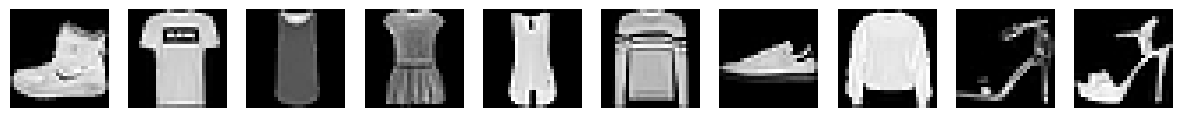

In [5]:
plt.figure(figsize=(15, 2))

for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(X_train[i].squeeze(), cmap='gray')
    plt.axis('off')

plt.show()

Se aprecia gran variedad de prendas y formas distintas, por lo que el modelo deberá aprender a reconstruirlas con el mayor detalle posible, que es lo que medirá el SSIM.

**2. DEFINICIÓN DEL ENCODER, DECODER Y SAMPLING**

En esta sección se definen las partes principales del modelo: el encoder, el decoder y la capa Sampling.



*   **Encoder**



El encoder comprime cada imagen de entrada de 784 valores (28x28) en un espacio latente de 10 dimensiones.

Tras aplanar las imágenes con Flatten, se pasan por dos capas densas de 150 y 100 neuronas con activación ReLU, que permite capturar patrones no lineales.

Finalmente, se generan los dos vectores de salida de tamaño 10: z_mean (media de la distribución latente) y z_log_var (logaritmo de la varianza). En este caso se utiliza el logaritmo de la varianza para evitar valores negativos.

In [6]:
codings_size = 10

def crear_encoder(codings_size):
    encoder_inputs = keras.layers.Input(shape=[28,28])
    x = layers.Flatten()(encoder_inputs)
    x = layers.Dense(150, activation="relu")(x)
    x = layers.Dense(100, activation="relu")(x)
    z_mean = layers.Dense(codings_size, name="z_mean")(x)
    z_log_var = layers.Dense(codings_size, name="z_log_var")(x)
    encoder = keras.Model(encoder_inputs, [z_mean, z_log_var], name="encoder")
    return encoder



*   **Capa Sampling**



Esta capa se encarga de generar el vector latente ${z}$ aplicando la técnica de reparametrización.

La capa recibe como entrada *z_mean* y *z_log_var* generados por el encoder, genera ruido aleatorio $\epsilon \sim \mathcal{N}(0,1)$ y calcula el vector ${z}$:

$$
z = z_{\text{mean}} + \sigma \odot \epsilon, \quad \sigma = \sqrt{\sigma^2} = \sqrt{e^{\, z_{\text{log\_var}}}} = e^{0.5 \, z_{\text{log\_var}}}
$$

De esta forma se consigue que la red sea entrenable mediante retropropagación.

In [7]:
class Sampling(layers.Layer):
    """Uses (z_mean, z_log_var) to sample z, the vector encoding a digit."""

    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.seed_generator = keras.random.SeedGenerator(42)

    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = ops.shape(z_log_var)[0]
        dim = ops.shape(z_log_var)[1]
        epsilon = keras.random.normal(shape=(batch, dim), seed=self.seed_generator)
        return z_mean + ops.exp(0.5 * z_log_var) * epsilon



*  **Decoder**



El decoder invierte el proceso seguido por el encoder, expandiendo la representación del vector latente ${z}$ de esta forma:  
10 dimensiones → 100 neuronas → 150 neuronas → 784 elementos (28x28), obteniendo la imagen reconstruida.

In [8]:
def crear_decoder(codings_size):
    latent_inputs = keras.layers.Input(shape=(codings_size,))
    x = tf.keras.layers.Dense(100, activation="relu")(latent_inputs)
    x = tf.keras.layers.Dense(150, activation="relu")(x)
    x = tf.keras.layers.Dense(28 * 28)(x)
    outputs = tf.keras.layers.Reshape([28, 28])(x)
    decoder = keras.Model(latent_inputs, outputs)
    return decoder

**3. DEFINICIÓN DEL MODELO β-VAE**

En esta sección se define el modelo β-VAE, combinando el encoder, el decoder y la capa Sampling definidos anteriormente. Además del encoder y el decoder, recibe el parámetro β para controlar el peso de la divergencia KL.

En el entrenamiento (train_step), el modelo obtiene la representación comprimida de las imágenes de entrada, las reconstruye y calcula la pérdida como error de reconstrucción + β * divergencia KL/784.

También se aplica test_step para evaluar el modelo en el conjunto de validación.

In [9]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta = 1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.sampling = Sampling()
        self.beta = beta # controla el peso de la divergencia KL en la pérdida
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    def set_beta(self, beta):
        self.beta = beta # permite cambiar beta sin reejutar el modelo

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def train_step(self, data):
        x, y = data
        with tf.GradientTape() as tape:
            # Encoder: obtiene la media y varianza de la distribución latente
            z_mean, z_log_var = self.encoder(x)

            # Sampling: muestrea z mediante reparametrización
            z = self.sampling([z_mean, z_log_var])

            # Decoder: reconstruye la imagen a partir de z
            reconstruction = self.decoder(z)

            # Error de reconstrucción: MSE entre imagen original y reconstruida
            reconstruction_loss = tf.keras.ops.mean(tf.keras.ops.square(x - reconstruction))

            # Divergencia KL: mide cuánto se aleja la distribución latente de N(0,1)
            # Se normaliza dividiendo entre 784 (nº de píxeles) para equilibrarla con el MSE
            kl_loss = -0.5 * (1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var))
            kl_loss = ops.mean(ops.sum(kl_loss, axis=1))

            # Pérdida total: beta pondera cuánto influye la KL respecto a la reconstrucción
            total_loss = reconstruction_loss + self.beta * tf.keras.ops.mean(kl_loss)/784.

        # Calcula gradientes y actualiza los pesos
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def test_step(self, data):
        X, y = data
        y_pred = self(X, training=False)

        for metric in self.metrics:
            metric.update_state(y, y_pred)
        return {m.name: m.result() for m in self.metrics}

    def call(self, inputs, *args, **kwargs):
        z_mean, z_log_var = self.encoder(inputs)
        z = self.sampling([z_mean, z_log_var])
        return self.decoder(z)

**4. ENTRENAMIENTO DE LA RED PARA DISTINTOS β**

En esta sección vamos a analizar cómo el hiperparámetro β influye en el comportamiento del modelo, ya que va a decidir si es más importante que las imágenes reconstruidas sean muy parecidas a las originales o que el espacio latente tenga una estructura ordenada y aproximada a una distribución normal estándar.

Para llevar a cabo este análisis, entrenamos modelos con estos seis valores de β:



*  β = 0 (Autoencoder clásico): ignora la divergencia KL, por lo que el modelo se preocupa solo de reconstruir las imágenes de forma precisa. Se espera que las reconstrucciones sean muy fieles pero el espacio latente no quedará ordenado, lo que dificulta generar nuevas imágenes.


*  β = 0.5: se introduce un poco de orden sobre el espacio latente, pero sigue siendo de mayor prioridad la calidad de las reconstrucciones.


*  β = 1 (VAE): se busca un equilibrio entre reconstrucción y regularización del espacio latente, es decir, ambas tienen la misma importancia.


*   β = 2 y β = 6: se aumenta el peso sobre la divergencia KL, haciendo que cada dimensión del espacio latente empiece a representar características más concretas. Esto puede hacer que las reconstrucciones pierdan nitidez, pero mejora la organización del espacio.

*  β = 11: el modelo prioriza mucho la estructura del espacio latente y las reconstrucciones pueden perder detalles.

Entrenamos los modelos durante 25 épocas, con optimizador Nadam y un tamaño de lote de 128 imágenes:

In [10]:
beta_values = [0, 0.5, 1, 2, 6, 11]
histories = {}
models = {}

for b in beta_values:
    print(f"Entrenando modelo con beta = {b}...")
    enc = crear_encoder(codings_size)
    dec = crear_decoder(codings_size)
    vae_model = VAE(enc, dec, beta=b)
    vae_model.compile(optimizer=keras.optimizers.Nadam())

    histories[f'beta_{b}'] = vae_model.fit(
        X_train, X_train,
        epochs=25,
        batch_size=128,
        validation_data=(X_valid, X_valid),
        verbose=0
    )
    models[f'beta_{b}'] = vae_model

Entrenando modelo con beta = 0...
Entrenando modelo con beta = 0.5...
Entrenando modelo con beta = 1...
Entrenando modelo con beta = 2...
Entrenando modelo con beta = 6...
Entrenando modelo con beta = 11...


Graficamos la evolución de la pérdida a lo largo de las 25 épocas para cada valor de β:

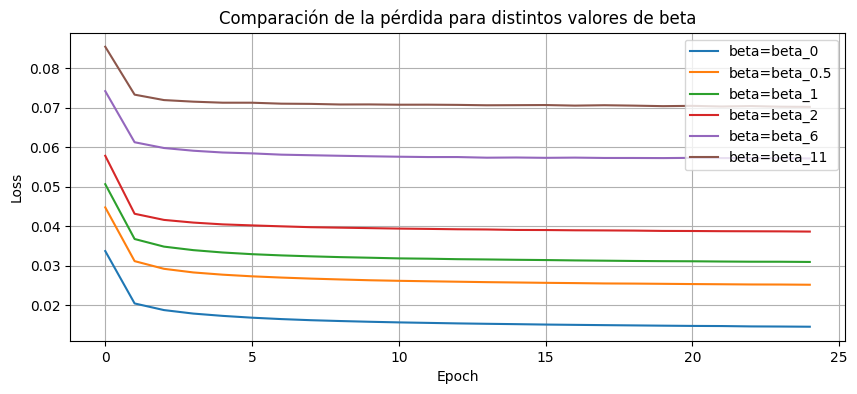

In [11]:
plt.figure(figsize=(10,4))

for b, hist in histories.items():
    plt.plot(hist.history['loss'], label=f'beta={b}')

plt.title('Comparación de la pérdida para distintos valores de beta')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

Se observa que todos los modelos convergen de forma estable a lo largo de las 25 épocas. Las curvas se van aplanando a partir de la época 5-10, lo que indica que el entrenamiento ha ido bien en todos los casos.  
Los modelos con β bajos (0 y 0.5) tienen las pérdidas más pequeñas (0.016 y 0.025), ya que dedican toda su capacidad a reconstruir las imágenes. El modelo con β=1 se sitúa en un punto intermedio (0.031).
Por otro lado, a  medida que β aumenta (2, 6 y 11), la pérdida total es mayor, porque se está priorizando la regularización del espacio latente a costa de perder precisión en las reconstrucciones.


**5. EVALUACIÓN DEL MODELO**

Para medir la calidad de las reconstrucciones se utiliza SSIM, que a diferencia del error cuadrático medio (MSE), tiene en cuenta la luminosidad, el contraste y la estructura de la imagen (además de las diferencias en los píxeles). Sus valores están entre 0 y 1, donde 1 indica que la imagen reconstruida es idéntica a la original.  
Se calculará la media y la desviación típica del SSIM sobre las 50 primeras imágenes del conjunto de validación para cada valor de β.

In [12]:
X_sample = X_valid[:50]

Antes de calcular el SSIM se visualizan las reconstrucciones obtenidas por cada modelo. Cada gráfico muestra en la primera fila las imágenes originales y en la segunda las reconstruidas:

In [13]:
def plot_reconstructions(model, images=X_valid, n_images=5):
    predictions = model.predict(images[:n_images]) # pasa las primeras n_images por el VAE para reconstruirlas
    reconstructions = np.clip(predictions, 0, 1) # asegura que los valores estén entre 0 y 1
    fig = plt.figure(figsize=(n_images * 1.5, 3))
    for image_index in range(n_images): # gráfico con 2 filas (primera imagenes originales, segunda reconstruidas)
        plt.subplot(2, n_images, 1 + image_index)
        plt.imshow(images[image_index], cmap="binary")
        plt.axis("off")
        plt.subplot(2, n_images, 1 + n_images + image_index)
        plt.imshow(reconstructions[image_index], cmap="binary")
        plt.axis("off")

=== Reconstrucciones para beta = 0 ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


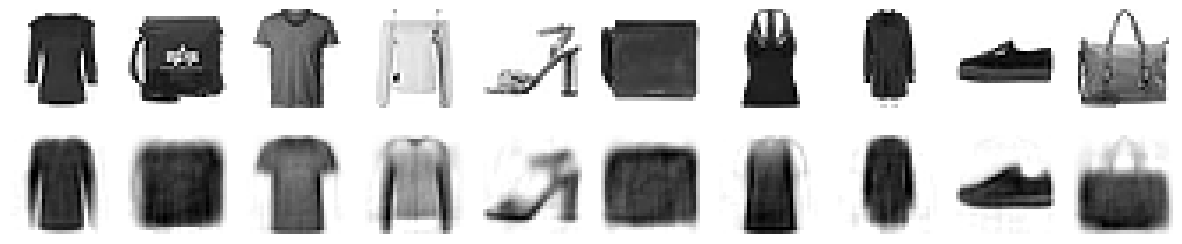

=== Reconstrucciones para beta = 0.5 ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 773ms/step


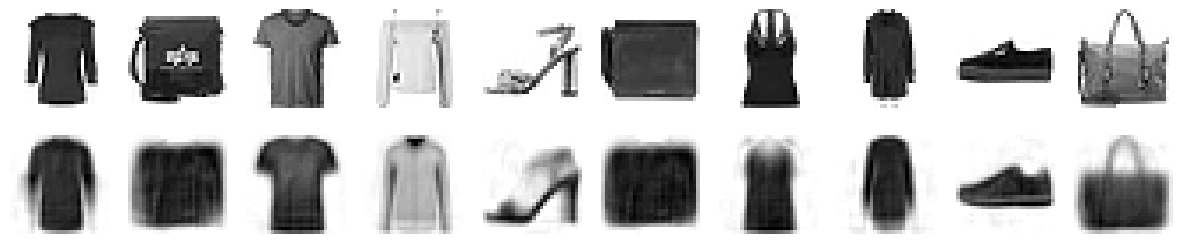

=== Reconstrucciones para beta = 1 ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 812ms/step


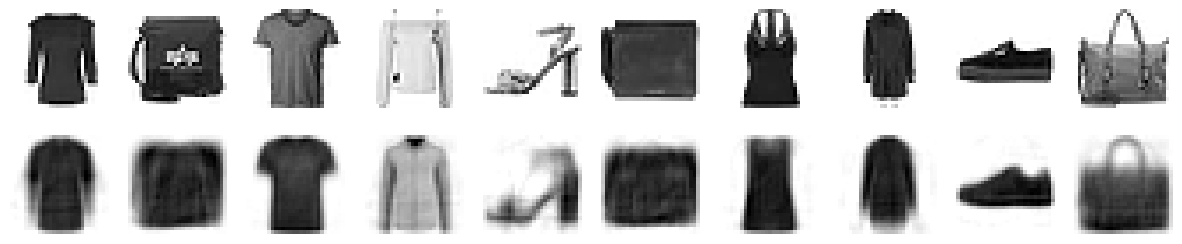

=== Reconstrucciones para beta = 2 ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 842ms/step


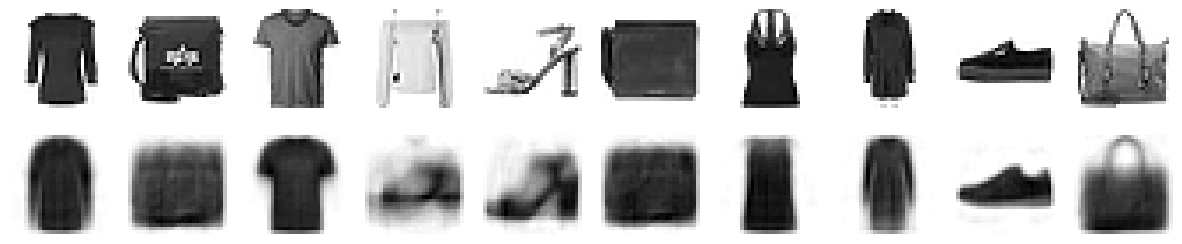

=== Reconstrucciones para beta = 6 ===


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 825ms/step


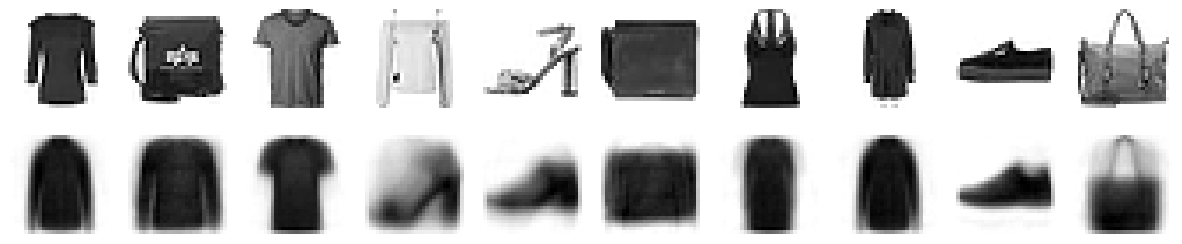

=== Reconstrucciones para beta = 11 ===


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 799ms/step


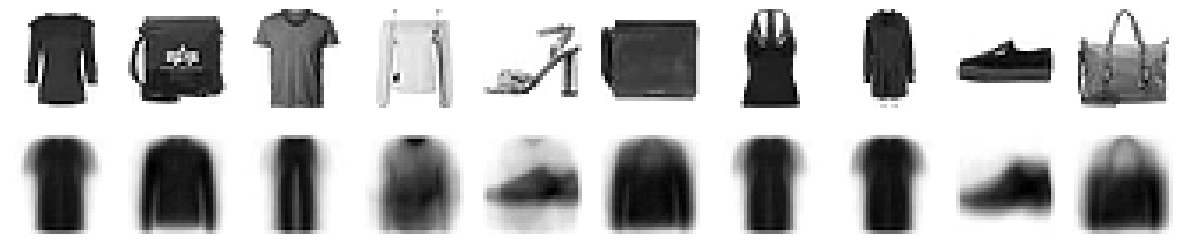

In [14]:
for b in beta_values:
    print(f"=== Reconstrucciones para beta = {b} ===")
    plot_reconstructions(models[f'beta_{b}'], X_sample, n_images=10)
    plt.show()

Se aprecia que con β=0 el modelo acierta en la mayoría de prendas y conserva sus formas, aunque las imágenes ya tienen menos nitidez que las originales.    
Con β=0.5 y β=1 los resultados son similares, aunque se pierde algo de detalle, especialmente en prendas más complejas como el bolso o el zapato de tacón.   
A partir de β=2 la calidad empeora de forma más notable y las reconstrucciones son más borrosas.   
Con β=6 y β=11 las imágenes apenas se parecen al original, e incluso algunas prendas las confunde con otras, como ocurre con el zapato de tacón en β=11.   


A continuación analizamos esta diferencia visual calculando el SSIM para cada modelo:

In [15]:
def calcular_ssim(model, X_sample):
    X_pred = model.predict(X_sample)

    # Añade dimensión de canal (50, 28, 28) → (50, 28, 28, 1)
    img_true = tf.expand_dims(tf.convert_to_tensor(X_sample, dtype=tf.float32), -1)  # (50, 28, 28, 1)
    img_pred = tf.expand_dims(tf.convert_to_tensor(X_pred, dtype=tf.float32), -1)    # (50, 28, 28, 1)

    # Calcula el SSIM para cada par de imágenes
    ssim_values = tf.image.ssim(img_true, img_pred, max_val=1.0).numpy()
    return np.mean(ssim_values), np.std(ssim_values)

In [16]:
results = {}

for b in beta_values:
    mean, std = calcular_ssim(models[f'beta_{b}'], X_sample)
    results[b] = {'mean': mean, 'std': std}
    print(f"Beta = {b}: Media SSIM = {mean:.4f}, Desviación = {std:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 968ms/step
Beta = 0: Media SSIM = 0.5981, Desviación = 0.1965
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 729ms/step
Beta = 0.5: Media SSIM = 0.5474, Desviación = 0.2004
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 721ms/step
Beta = 1: Media SSIM = 0.5175, Desviación = 0.1907
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 714ms/step
Beta = 2: Media SSIM = 0.4771, Desviación = 0.1895
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 713ms/step
Beta = 6: Media SSIM = 0.3953, Desviación = 0.1649
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 724ms/step
Beta = 11: Media SSIM = 0.2794, Desviación = 0.1770


In [17]:
betas = list(results.keys())
means = [results[b]['mean'] for b in betas]
stds = [results[b]['std'] for b in betas]

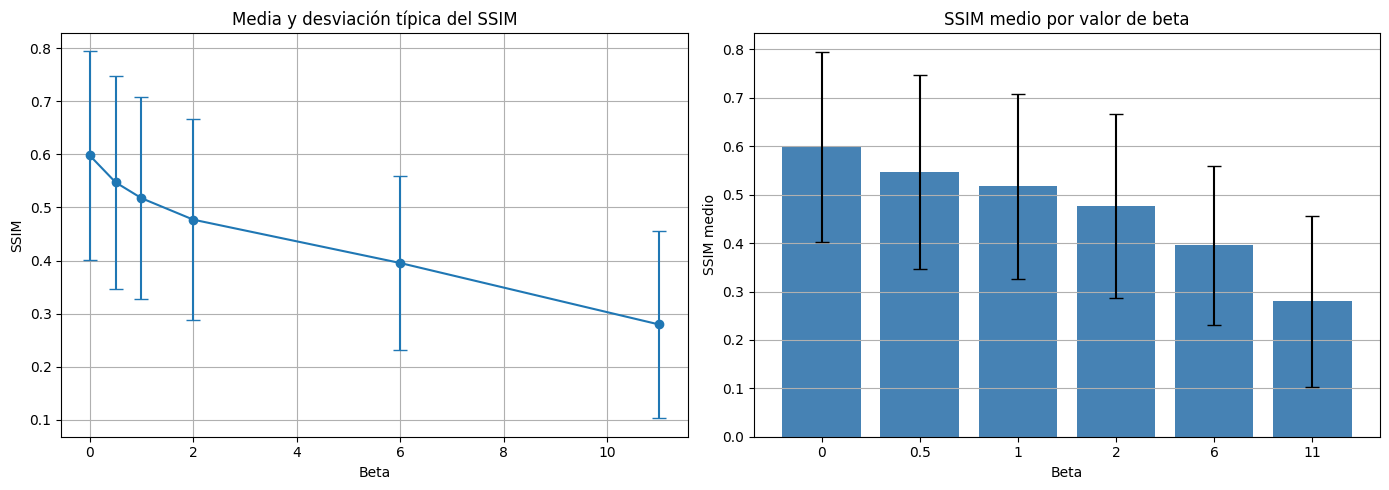

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Errorbar
ax1.errorbar(betas, means, yerr=stds, fmt='o-', capsize=5)
ax1.set_xlabel('Beta')
ax1.set_ylabel('SSIM')
ax1.set_title('Media y desviación típica del SSIM')
ax1.grid(True)

# Barras
ax2.bar([str(b) for b in betas], means, yerr=stds, capsize=5, color='steelblue')
ax2.set_xlabel('Beta')
ax2.set_ylabel('SSIM medio')
ax2.set_title('SSIM medio por valor de beta')
ax2.grid(True, axis='y')

plt.tight_layout()
plt.show()

A medida que β aumenta se observa cómo baja el SSIM, tanto en los gráficos como en los valores. Entre β=0 (0.598), β=0.5 (0.547) y β=1 (0.518) las diferencias son pequeñas, lo que explica que visualmente las reconstrucciones fueran bastante parecidas, mientras que a partir de β=2 la caída es más grande.  
Es importante destacar que ningún modelo alcanza un SSIM alto, ya que incluso el mejor resultado (β=0 con SSIM=0.598) indica que en promedio las imágenes reconstruidas tienen solo un 60% de similitud con las originales.   
A partir de β=2 (SSIM=0.477) empeora notablemente, ya que un valor por debajo de 0.5 indica que la reconstrucción tiene menos de la mitad de similitud en estructura respecto a la imagen original, lo que provoca imágenes borrosas.   
Con β=11 (0.279) los resultados apenas se asemejan a los originales.   
Respecto a la desviación típica, se mantiene en torno a 0.18-0.20 en todos los casos, lo cual se puede ver en las barras de error del gráfico, que son similares en altura. Esto indica que hay imágenes que siempre se reconstruyen mejor que otras.

A continuación se muestra cómo se distribuye el espacio latente para β=0 y β=11:

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


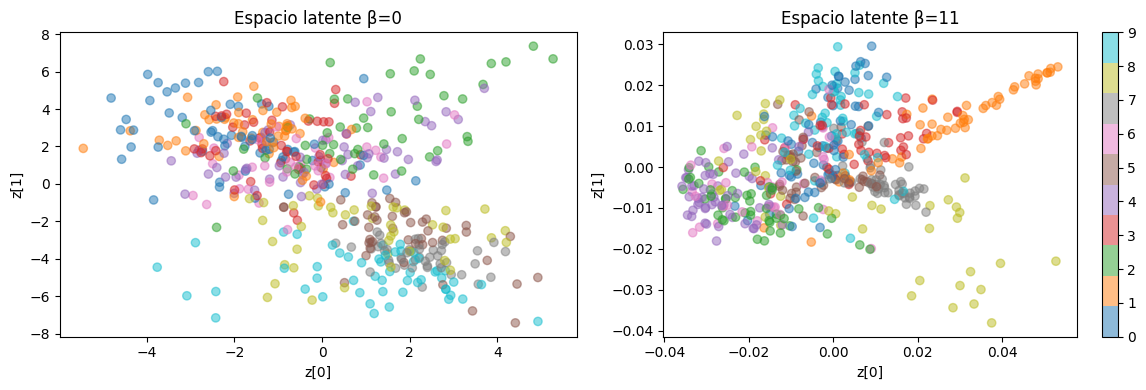

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, b in zip(axes, [0, 11]):
    z_mean, _ = models[f'beta_{b}'].encoder.predict(X_valid[:500])
    scatter = ax.scatter(z_mean[:, 0], z_mean[:, 1],
                        c=y_valid[:500], cmap='tab10', alpha=0.5)
    ax.set_title(f'Espacio latente β={b}')
    ax.set_xlabel('z[0]')
    ax.set_ylabel('z[1]')

plt.colorbar(scatter, ax=axes[1])
plt.tight_layout()
plt.show()

Se aprecia que con β=0 los puntos están más dispersos, mientras que con β=11 se agrupan más, lo que facilita la generación de imágenes, pero como hemos visto, las reconstrucciones son mucho peores.

En este análisis el objetivo es obtener las mejores reconstrucciones, por lo que el mejor modelo es con β=0 (autoencoder clásico) que es el que tiene mejor SSIM, pero si el objetivo fuese generar imágenes nuevas, necesitaríamos un β mayor.

**6. COMPARACIÓN DE OPTIMIZADORES**

Hasta ahora se ha usado Nadam como optimizador para entrenar los modelos, que se encarga de controlar cómo se actualizan los pesos de la red durante el entrenamiento. Para comprobar si los resultados mejoran con otros optimizadores, se entrena el mejor modelo (β=0) con Adam y RMSprop y se comparan los resultados mediante el SSIM. Además, se mantienen el mismo número de épocas (25) y tamaño de lote (128) para que la comparación sea justa.



*  Optimizador Adam



In [20]:
variational_ae_adam = VAE(crear_encoder(codings_size), crear_decoder(codings_size), beta=0)
variational_ae_adam.compile(optimizer=keras.optimizers.Adam())
history_adam = variational_ae_adam.fit(X_train, X_train, epochs=25, batch_size=128,
                             validation_data=(X_valid, X_valid), verbose=0)

Reconstrucciones y SSIM con Adam:

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 799ms/step
Adam - Media SSIM = 0.5930, Desviación = 0.1913
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 731ms/step


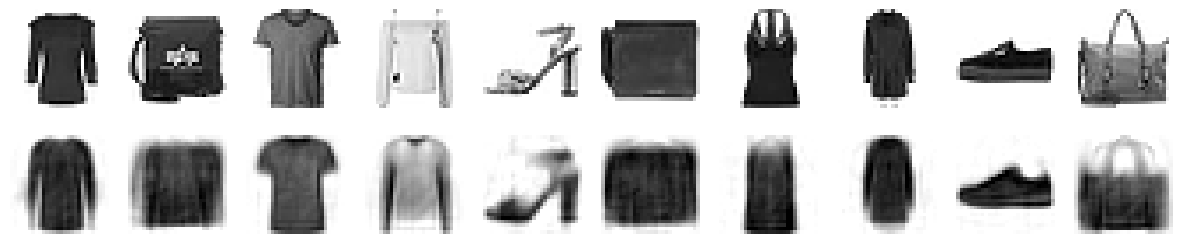

In [21]:
mean_adam, std_adam = calcular_ssim(variational_ae_adam, X_sample)
print(f"Adam - Media SSIM = {mean_adam:.4f}, Desviación = {std_adam:.4f}")
plot_reconstructions(variational_ae_adam, X_sample, n_images=10)
plt.show()



*   Optimizador RMSprop



In [22]:
variational_ae_rms = VAE(crear_encoder(codings_size), crear_decoder(codings_size), beta=0)
variational_ae_rms.compile(optimizer=keras.optimizers.RMSprop())
history_rms = variational_ae_rms.fit(X_train, X_train, epochs=25, batch_size=128,
                             validation_data=(X_valid, X_valid), verbose=0)

Reconstrucciones y SSIM con RMSprop:

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 801ms/step
RMSprop - Media SSIM = 0.5340, Desviación = 0.1817
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 693ms/step


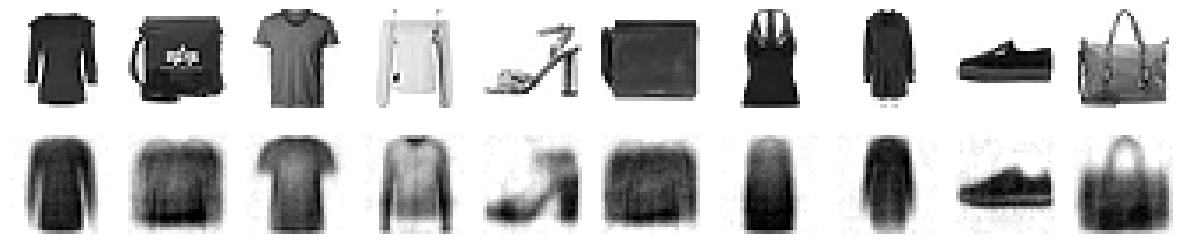

In [23]:
mean_rms, std_rms = calcular_ssim(variational_ae_rms, X_sample)
print(f"RMSprop - Media SSIM = {mean_rms:.4f}, Desviación = {std_rms:.4f}")
plot_reconstructions(variational_ae_rms, X_sample, n_images=10)
plt.show()

Tabla comparativa:

| Optimizador | Media SSIM | Desviación SSIM |
|-----------|------------|----------------|
| Nadam     | 0.598     | 0.197         |
| Adam      | 0.593    | 0.191         |
| RMSprop   | 0.534     | 0.182         |

Los resultados muestran que Nadam y Adam obtienen un rendimiento muy similar (0.598 y 0.593 respectivamente), mientras que RMSprop queda por debajo (0.534).  
Esto tiene sentido teniendo en cuenta que Nadam y Adam siguen el mismo procedimiento de descenso de gradiente con momento adaptativo. RMSprop en cambio adapta el learning rate por parámetro pero sin momento, lo que puede hacer que obtenga un peor resultado.    
Respecto a la desviación típica, los tres optimizadores obtienen valores similares (0.18-0.20), lo que indica que la variabilidad entre imágenes no depende del optimizador sino de la dificultad de cada prenda. Por ello, se mantiene que el mejor modelo es β=0 con optimizador Nadam.

**7. AJUSTE DEL LEARNING RATE**

Una vez identificado el mejor modelo (β=0 con Nadam), se busca el learning rate más adecuado para mejorar los resultados. Este parámetro controla cuánto ajusta la red sus pesos en cada paso de forma que si la tasa es muy grande el modelo puede no aprender bien, y si es muy pequeña el entrenamiento puede ser lento.    

El LR por defecto de Nadam es 0.001, pero para ver si mejoran los resultados con otro valor entrenamos un modelo desde cero aumentando el learning rate de forma exponencial, partiendo de un valor muy bajo (0.00001) hasta valores más altos. Después, observamos cómo evoluciona la pérdida para ver en qué punto el modelo empieza a aprender y cuándo la pérdida se empieza a disparar.


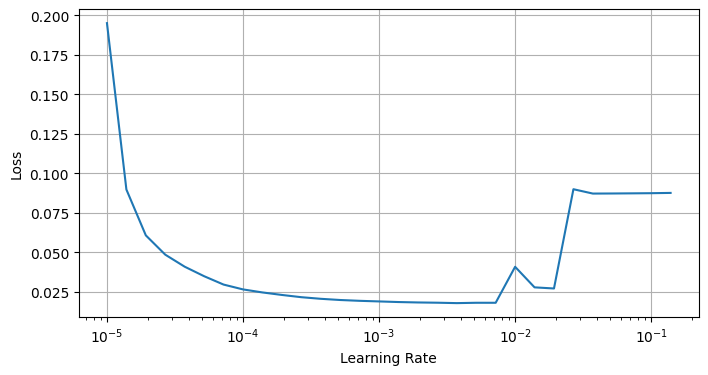

In [24]:
lr_finder_model = VAE(crear_encoder(codings_size), crear_decoder(codings_size), beta=0)
lr_finder_model.compile(optimizer=keras.optimizers.Nadam(learning_rate=1e-5))

lr_schedule = keras.callbacks.LearningRateScheduler(
    lambda epoch: 1e-5 * 10**(epoch / 7)
)

history_lr = lr_finder_model.fit(
    X_train, X_train,
    epochs=30,
    batch_size=128,
    callbacks=[lr_schedule],
    verbose=0
)

lrs = [1e-5 * 10**(epoch / 7) for epoch in range(30)]

plt.figure(figsize=(8, 4))
plt.semilogx(lrs, history_lr.history['loss'])
plt.xlabel('Learning Rate')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

La pérdida cae desde LR=10⁻⁵ (0.2) hasta LR=10⁻³ (0.02), donde se estabiliza. A partir de LR=10⁻² aparece un pico de inestabilidad, lo que indica que el modelo empieza a divergir con ese learning rate.
Por tanto, el LR óptimo se sitúa antes de ese punto de inestabilidad, en torno a 10⁻³–10⁻², que coincide aproximadamente con el valor por defecto de Nadam (0.001). Se prueba con 0.01 para ver si mejora:

In [25]:
model_mejor_lr = VAE(crear_encoder(codings_size), crear_decoder(codings_size), beta=0)
model_mejor_lr.compile(optimizer=keras.optimizers.Nadam(learning_rate=0.01))

history_mejor_lr = model_mejor_lr.fit(
    X_train, X_train,
    epochs=25,
    batch_size=128,
    validation_data=(X_valid, X_valid),
    verbose=0
)

mean_mejor_lr, std_mejor_lr = calcular_ssim(model_mejor_lr, X_sample)
print(f"LR=0.01 - Media SSIM = {mean_mejor_lr:.4f}, Desviación = {std_mejor_lr:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 828ms/step
LR=0.01 - Media SSIM = 0.5543, Desviación = 0.1718


Tabla comparativa:

| Learning Rate | Media SSIM | Desviación SSIM |
|--------------|------------|----------------|
| 0.001 (por defecto) | 0.598 | 0.197|
| 0.01 (óptimo) | 0.554| 0.172 |

Con LR=0.01, el SSIM baja de 0.598 a 0.554, por lo que el learning rate por defecto de Nadam (0.001) sigue siendo el mejor. Esto puede deberse a que 0.01 estaba muy cerca del punto de inestabilidad.   
Por tanto, el modelo estaba ya bien configurado desde el principio con el learning rate por defecto y no ha sido posible mejorarlo mediante la búsqueda del LR.

**8. CONCLUSIONES**

Tras entrenar un β-VAE con distintos valores de β sobre Fashion-MNIST, los resultados muestran claramente que cuanto mayor es β peor es la calidad de reconstrucción.   

El mejor modelo se obtiene con β=0 (autoencoder clásico con SSIM=0.598), lo que tiene sentido ya que al eliminar el término KL el modelo se centra en reducir el error de reconstrucción. Sin embargo, con β=0 el espacio latente no sigue una distribución ordenada, por lo que si quisiéramos generar nuevas imágenes habría que seleccionar un β mayor a pesar de obtener peor SSIM.


Aun así, los valores de SSIM son bajos en todos los modelos (el mejor se aproxima a 0.6), lo que puede indicar que los autoencoders con capas densas pueden no ser los más adecuados para este tipo de imágenes.

En cuanto a los optimizadores, Nadam y Adam se comportan de forma muy parecida (0.598 y 0.593), mientras que RMSprop es el que peor resultado obtiene (0.534).    
Respecto al learning rate, la búsqueda del LR óptimo no consiguió mejorar los resultados.

En conclusión, parece que el tipo de modelo tiene mayor impacto en la calidad de reconstrucción más que la elección del optimizador o el ajuste del learning rate.


